# Preparing data for a machine learning model. — Additional questions

This notebook comes from the article [Preparing data for a machine learning model.](https://www.jeremyjordan.me/preparing-data-for-a-machine-learning-model/)

Dataset in Kagle: [Mental Health in Tech Survey](https://www.kaggle.com/datasets/osmi/mental-health-in-tech-survey/data)

Article from: 30 May 2017. This is using a much older version of Pandas, so some of the code may not work with the current version. I will try to update it as I go along.

In the dataset there are 2 questions:

1. How does the frequency of mental health illness and attitudes towards mental health vary by geographic location?
2. What are the strongest predictors of mental health illness or certain attitudes towards mental health in the workplace?

## Question 1

### Frequency of mental health illness by geographic location

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("./data/week_2_survey.csv")
#num_columns = len(df.columns)
#pd.set_option("display.max_columns", num_columns)
df.head(30)

,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,2014-08-27 11:29:31,37,Female,United States,IL,NaN,No,Yes,Often,6-25,...,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,2014-08-27 11:29:37,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,...,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,2014-08-27 11:29:44,32,Male,Canada,NaN,NaN,No,No,Rarely,6-25,...,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,2014-08-27 11:29:46,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,...,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,2014-08-27 11:30:22,31,Male,United States,TX,NaN,No,No,Never,100-500,...,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN
5,2014-08-27 11:31:22,33,Male,United States,TN,NaN,Yes,No,Sometimes,6-25,...,Don't know,No,No,Yes,Yes,No,Maybe,Don't know,No,NaN
6,2014-08-27 11:31:50,35,Female,United States,MI,NaN,Yes,Yes,Sometimes,1-5,...,Somewhat difficult,Maybe,Maybe,Some of them,No,No,No,Don't know,No,NaN
7,2014-08-27 11:32:05,39,M,Canada,NaN,NaN,No,No,Never,1-5,...,Don't know,No,No,No,No,No,No,No,No,NaN
8,2014-08-27 11:32:39,42,Female,United States,IL,NaN,Yes,Yes,Sometimes,100-500,...,Very difficult,Maybe,No,Yes,Yes,No,Maybe,No,No,NaN
9,2014-08-27 11:32:43,23,Male,Canada,NaN,NaN,No,No,Never,26-100,...,Don't know,No,No,Yes,Yes,Maybe,Maybe,Yes,No,NaN


**You can’t assume all participants have a mental health condition.** This 2014 dataset also doesn’t have a direct column confirming whether each respondent has one.

The closest field is `treatment`, which asks whether the respondent has sought treatment for a mental health condition. `work_interfere` asks how a condition interferes with work.

In [2]:
columns_to_show = [
    "Country", "self_employed", "family_history", "work_interfere",
    "no_employees", "remote_work", "tech_company", "benefits",
    "care_options", "wellness_program", "seek_help", "anonymity",
    "leave", "mental_health_consequence", "phys_health_consequence",
    "coworkers", "supervisor", "mental_health_interview",
    "phys_health_interview", "mental_vs_physical", "obs_consequence",
]

df.loc[df["treatment"] == "Yes", columns_to_show]

,Country,self_employed,family_history,work_interfere,no_employees,remote_work,tech_company,benefits,care_options,wellness_program,...,anonymity,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence
0,United States,NaN,No,Often,6-25,No,Yes,Yes,Not sure,No,...,Yes,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No
3,United Kingdom,NaN,Yes,Often,26-100,No,Yes,No,Yes,No,...,No,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes
6,United States,NaN,Yes,Sometimes,1-5,Yes,Yes,No,No,No,...,No,Somewhat difficult,Maybe,Maybe,Some of them,No,No,No,Don't know,No
8,United States,NaN,Yes,Sometimes,100-500,No,Yes,Yes,Yes,No,...,No,Very difficult,Maybe,No,Yes,Yes,No,Maybe,No,No
10,United States,NaN,No,Sometimes,6-25,Yes,Yes,Don't know,No,No,...,Don't know,Don't know,No,No,Some of them,Yes,No,No,Don't know,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1252,United States,No,Yes,Sometimes,100-500,Yes,Yes,Yes,Yes,Yes,...,Yes,Don't know,Yes,No,Some of them,No,No,Maybe,No,No
1254,United Kingdom,No,No,NaN,26-100,No,Yes,No,No,No,...,Don't know,Somewhat easy,No,No,Some of them,Some of them,No,No,Don't know,No
1255,United States,No,Yes,Often,26-100,Yes,Yes,Yes,Yes,No,...,Yes,Somewhat difficult,No,No,Some of them,Yes,No,No,Yes,No
1256,United States,No,Yes,Sometimes,More than 1000,No,Yes,Yes,Yes,No,...,Don't know,Somewhat difficult,Yes,Yes,No,No,No,No,No,No


In [3]:
country_counts = (
    df.loc[df["treatment"] == "Yes"]
    .groupby("Country")
    .size()
    .reset_index(name="Sought treatment")
    .sort_values("Sought treatment", ascending=False)
)

country_counts

,Country,Sought treatment
26,United States,410
25,United Kingdom,93
5,Canada,37
10,Germany,21
12,Ireland,13
0,Australia,13
17,Netherlands,9
18,New Zealand,5
22,South Africa,4
19,Poland,4


In [4]:
country_summary = (
    df.assign(sought_treatment=df["treatment"].map({"Yes": 1, "No": 0}))
    .groupby("Country")["sought_treatment"]
    .agg(
        Respondents="count",
        Sought_treatment="sum",
        Percentage="mean",
    )
)

country_summary["Percentage"] = (
    country_summary["Percentage"] * 100
).round(1)

country_summary.sort_values("Percentage", ascending=False)

,Respondents,Sought_treatment,Percentage
Country,,,
Japan,1,1,100.0
Croatia,2,2,100.0
Slovenia,1,1,100.0
Moldova,1,1,100.0
Denmark,2,2,100.0
Zimbabwe,1,1,100.0
"Bahamas, The",1,1,100.0
South Africa,6,4,66.7
New Zealand,8,5,62.5


In [5]:
min_respondents = 20

grouped_summary = (
    country_summary.assign(
        Country_group=country_summary.index.where(
            country_summary["Respondents"] >= min_respondents,
            "Other",
        )
    )
    .groupby("Country_group")[["Respondents", "Sought_treatment"]]
    .sum()
    .rename_axis("Country")
)

grouped_summary["Percentage"] = (
    grouped_summary["Sought_treatment"]
    / grouped_summary["Respondents"]
    * 100
).round(1)

grouped_summary.sort_values("Respondents", ascending=False)

,Respondents,Sought_treatment,Percentage
Country,,,
United States,751,410,54.6
United Kingdom,185,93,50.3
Other,131,41,31.3
Canada,72,37,51.4
Germany,45,21,46.7
Ireland,27,13,48.1
Netherlands,27,9,33.3
Australia,21,13,61.9


Again: **`treatment == "No"` does not mean “no mental illness.”**

This is because the survey question only asks whether the respondent has sought treatment for a mental health condition, not whether they have a mental health condition. Therefore, a respondent who answers "No" to the treatment question may still have a mental health condition that they have not sought treatment for.

### Attitudes towards mental health in the workplace

We compare attitudes towards mental health across countries using the following survey columns:

| Column | What it measures |
|---|---|
| `mental_health_consequence` | Whether respondents expect negative consequences from discussing mental health with their employer |
| `coworkers` | Willingness to discuss mental health with coworkers |
| `supervisor` | Willingness to discuss mental health with a direct supervisor |
| `mental_vs_physical` | Whether respondents believe their employer takes mental health as seriously as physical health |

This analysis includes **all respondents**, regardless of whether they have sought treatment.

Countries with fewer than **20 respondents** are combined into **Other**. For each question, we calculate the percentage of each response within each country group, excluding missing answers. Percentages therefore total approximately 100% per group.

A stacked horizontal bar chart shows how response distributions differ geographically. Percentages for **Other** are calculated from the pooled respondents, rather than by averaging country percentages.

Responses must be interpreted according to the question. For example, **Yes** to `mental_health_consequence` indicates an expectation of negative consequences, whereas **Yes** to `supervisor` indicates willingness to discuss mental health with a supervisor.

These results describe reported attitudes and workplace perceptions among survey respondents. They do not establish the attitudes of entire countries or the prevalence of mental illness.

In [6]:
attitude_meanings = {
    "mental_health_consequence": (
        "Expected negative consequences of discussing mental health with an employer"
    ),
    "coworkers": "Willingness to discuss mental health with coworkers",
    "supervisor": "Willingness to discuss mental health with your direct supervisor(s)",
    "mental_vs_physical": (
        "Whether the employer takes mental health as seriously as physical health"
    ),
}

def table_attitute_percentages(attitude, min_respondents=20):
    assert isinstance(attitude, str), "attitude must be a string"
    assert attitude in attitude_meanings.keys(), "attitude must be one of 'mental_health_consequence', 'coworkers', 'supervisor', or 'seek_help'"

    #attitude = "mental_health_consequence"

    # Use all respondents to examine attitudes.
    country_counts = df["Country"].value_counts()

    country_groups = df["Country"].where(
        df["Country"].map(country_counts) >= min_respondents,
        "Other",
    )

    # Within each country group, calculate the response percentages.
    attitude_percentages = (
        pd.crosstab(
            country_groups,
            df[attitude],
            normalize="index",
        )
        .mul(100)
        .round(1)
    )

    return attitude_percentages

def display_stacked_graph(attitude_percentages_df, attitude):
    assert isinstance(attitude, str), "attitude must be a string"

    attitude_percentages_df.plot.barh(
        stacked=True,
        figsize=(10, 6),
    )

    plt.xlabel("Respondents (%)")
    plt.ylabel("Country")
    plt.title(attitude_meanings[attitude])
    plt.legend(title="Response", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

attitude_percentages = table_attitute_percentages("mental_health_consequence")
display(attitude_percentages)

mental_health_consequence,Maybe,No,Yes
Country,,,
Australia,14.3,47.6,38.1
Canada,34.7,43.1,22.2
Germany,26.7,62.2,11.1
Ireland,37.0,22.2,40.7
Netherlands,33.3,51.9,14.8
Other,34.4,39.7,26.0
United Kingdom,39.5,37.3,23.2
United States,39.9,37.3,22.8


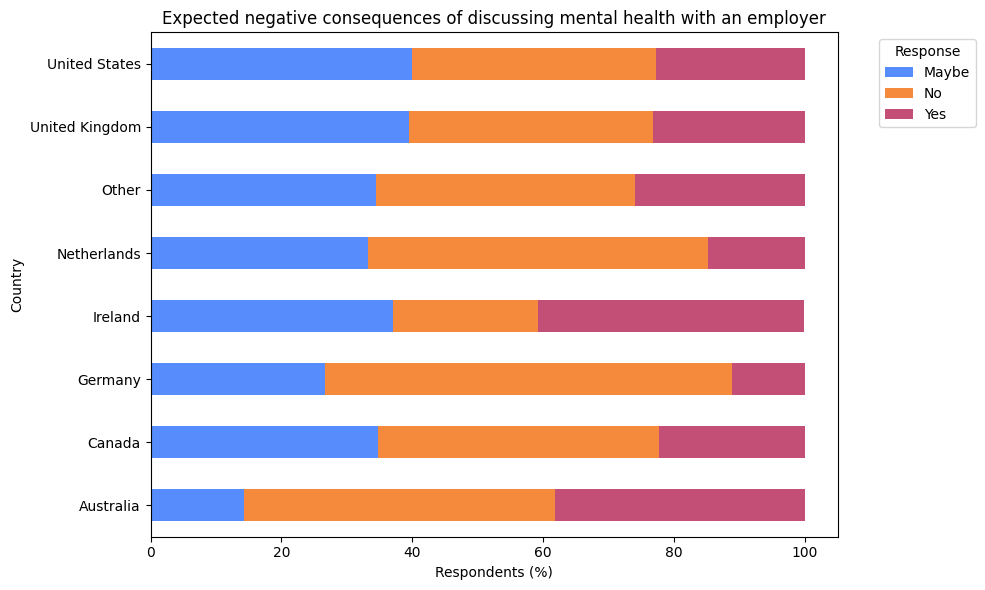

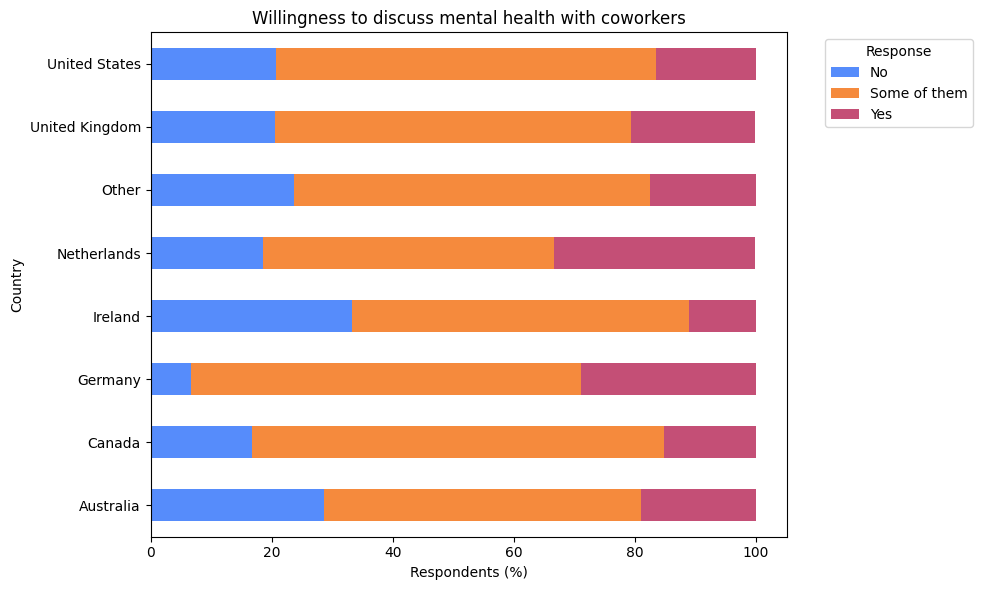

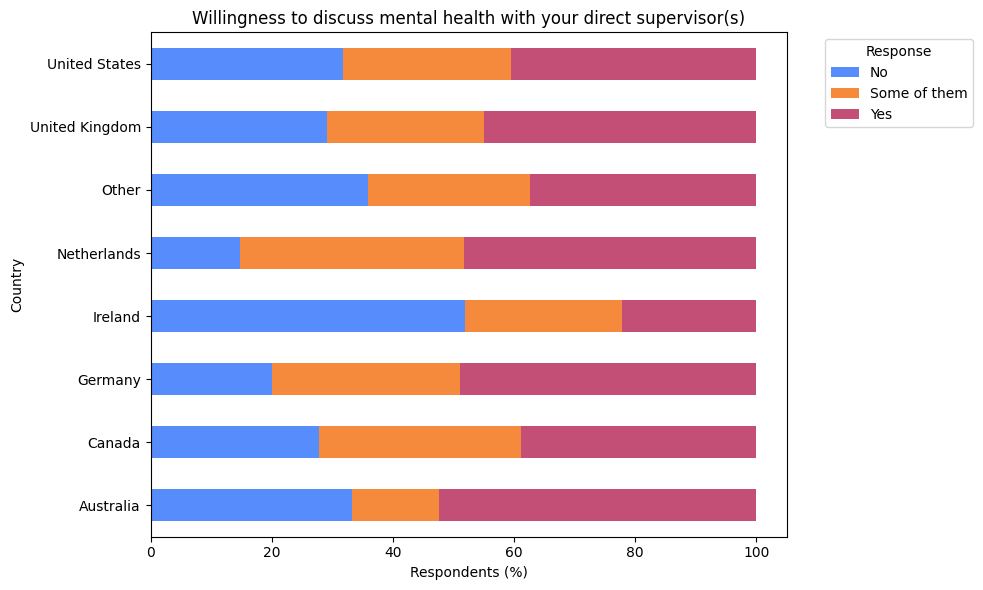

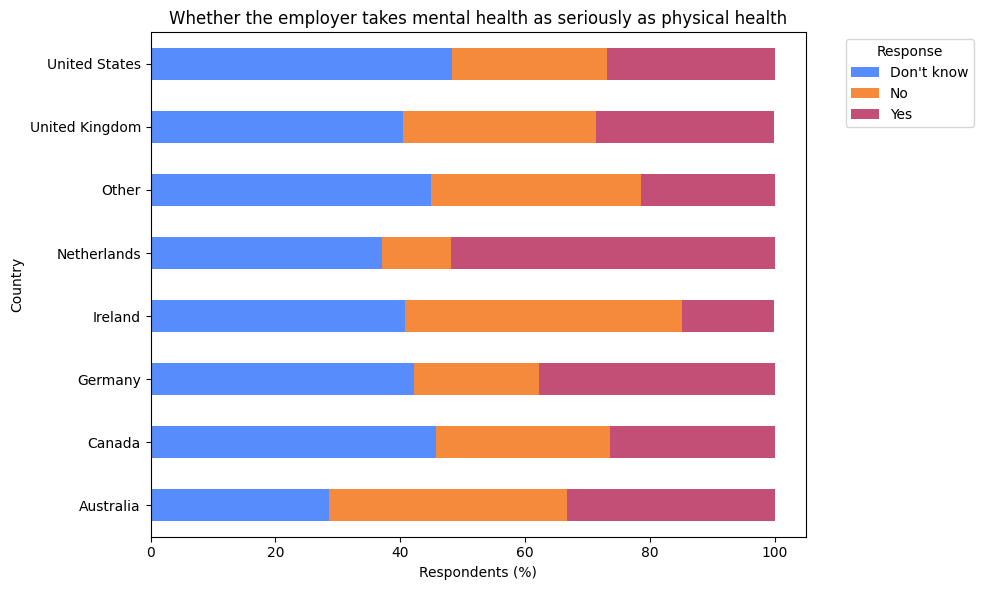

In [7]:
for attitude in attitude_meanings.keys():
    attitude_df = table_attitute_percentages(attitude)
    display_stacked_graph(attitude_df, attitude)

## Question 2

What are the strongest predictors of mental health illness or certain attitudes towards mental health in the workplace?

### Predictors of treatment seeking and workplace attitudes

This analysis examines which demographic, family-history, and workplace
characteristics help predict whether respondents sought mental health
treatment or report particular workplace attitudes.

The `treatment` column measures treatment seeking, not the presence of a
diagnosed mental illness.

We will evaluate predictive models on held-out data and rank predictors
using permutation importance. Variables whose shuffling produces the
largest decrease in predictive performance will be considered the most
important for that model.

These findings describe predictive associations among survey respondents.
They do not demonstrate that a characteristic causes mental illness,
treatment seeking, or a particular attitude.

### Example code

This trains a **logistic regression model** to predict treatment seeking, compares it with a baseline, and ranks predictors. It assumes your survey is loaded as df.

Preprocessing is fitted only on the training data to avoid leakage.

#### Encoding company size

The `no_employees` column contains ordered categories:

`1-5` → `6-25` → `26-100` → `100-500` → `500-1000` → `More than 1000`

Although ordinal encoding preserves this order, it introduces an additional assumption when used in logistic regression:

| Encoding | Assumption in logistic regression |
|---|---|
| **One-hot** — the current approach | Each size category can have its own relationship with treatment seeking |
| **Ordinal** | Every step up a category has the same effect on the predicted log-odds |

Encoding the categories as integers from 0 to 5 means that moving from **1–5 to 6–25** has the same modeled effect as moving from **500–1000 to more than 1,000**, despite the unequal company-size ranges. It also imposes a consistently increasing or decreasing relationship, unless the coefficient is zero.

One-hot encoding accommodates patterns such as respondents in medium-sized companies being more likely to seek treatment than those in either smaller or larger companies.

For this analysis, we retain **one-hot encoding as the baseline** because there are only six categories and we have not established a consistently increasing or decreasing relationship.

Ordinal encoding could be evaluated as an alternative using cross-validation on the training data. The low permutation importance of `no_employees` alone does not demonstrate that its encoding should change.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
)
from sklearn.inspection import permutation_importance

# 1. Select predictors and the outcome.
numeric_columns = ["Age"]
categorical_columns = [
    "Gender",
    "Country",
    "family_history",
    "self_employed",
    "no_employees",
    "remote_work",
    "tech_company",
    "benefits",
    "care_options",
    "wellness_program",
    "seek_help",
    "anonymity",
    "leave",
]

# Keep only respondents with a valid target response.
model_data = df.loc[df["treatment"].isin(["Yes", "No"])].copy()

X = model_data[numeric_columns + categorical_columns].copy()
y = model_data["treatment"].map({"No": 0, "Yes": 1})

# Treat ages outside this analysis's adult range as missing.
# The training-data median will fill them later.
X["Age"] = pd.to_numeric(X["Age"], errors="raise")
# Filter between 18 and 80 years old.
X.loc[~X["Age"].between(18, 80), "Age"] = np.nan

# 2. Reserve 25% for evaluation.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y, # If not None, data is split in a stratified fashion, using this as the class labels.
)

# 3. Define preprocessing.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing",
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns),
])

# 4. Train the complete pipeline.
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000)),
])

model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Gender', 'Country',
                                                   'family_history',
                                                   'self_employed',
                                                   'no_employees',
                                                   'remote_work',
                                                   'tech_company', 'benefits',
                                                   'care_options',
                                                   'wellness_program',
                                                   'seek_help', 'anonymity',
                                                   'leave'])])),
                ('classifier', LogisticRegression(max_iter=2000))])

Finally, estimate which original columns contribute most to the model’s test performance:

,Predictor,Mean AUC decrease,Standard deviation
3,family_history,0.1088,0.0192
9,care_options,0.0465,0.0115
13,leave,0.0205,0.0104
1,Gender,0.0181,0.0105
8,benefits,0.0083,0.0094
5,no_employees,0.0052,0.0030
12,anonymity,0.0031,0.0044
2,Country,0.0030,0.0060
0,Age,0.0018,0.0005
6,remote_work,0.0011,0.0016


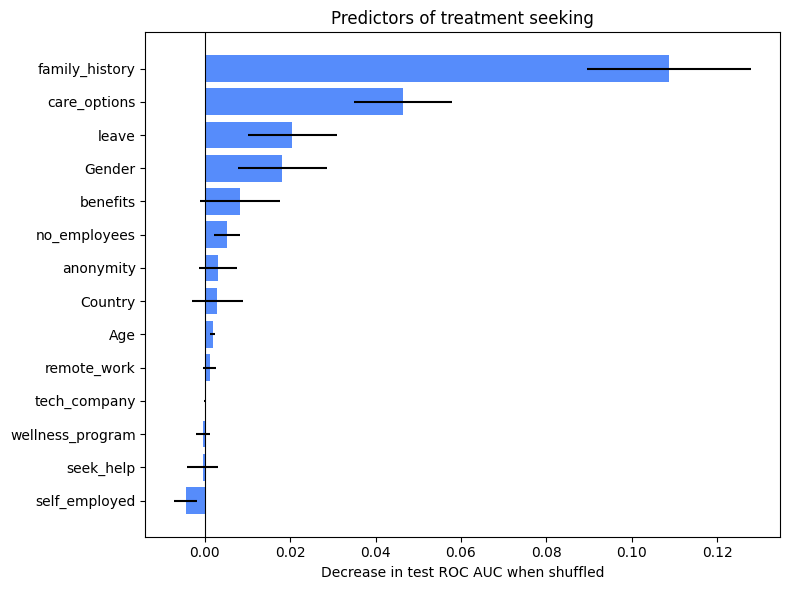

In [9]:
importance = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=20,
    random_state=42,
    n_jobs=1,
)

predictor_importance = pd.DataFrame({
    "Predictor": X_test.columns,
    "Mean AUC decrease": importance.importances_mean,
    "Standard deviation": importance.importances_std,
}).sort_values("Mean AUC decrease", ascending=False)

display(predictor_importance.round(4))

plot_data = predictor_importance.sort_values("Mean AUC decrease")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(
    plot_data["Predictor"],
    plot_data["Mean AUC decrease"],
    xerr=plot_data["Standard deviation"],
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(
    title="Predictors of treatment seeking",
    xlabel="Decrease in test ROC AUC when shuffled",
)
plt.tight_layout()
plt.show()

### Understanding the predictor importance chart

This chart shows how much the trained model relies on each column to predict whether a respondent sought mental health treatment.

We measure this using **permutation importance**:

1. Evaluate the model on the original test data.
2. Randomly rearrange—or **shuffle**—the values in one column among respondents. Keep the other columns and actual treatment responses unchanged.
3. Evaluate the same model again, without retraining it.
4. Measure how much its performance decreased.

Shuffling preserves the values in a column but disrupts their connection to the correct respondents. If predictions become worse, this suggests the model was using that column's information.

Performance is measured using **ROC AUC**, which describes how well the model ranks respondents who sought treatment above those who did not. A score of 0.5 represents chance-level ranking, while 1.0 represents perfect ranking.

### Reading the blue bars

Each blue bar shows the **average decrease in test ROC AUC** across 20 shuffles of that column.

| Bar position | Meaning |
|---|---|
| **Longer bar to the right of zero** | Shuffling substantially reduced performance, suggesting the model relies more on this column |
| **Short bar near zero** | Shuffling made little difference, suggesting little additional predictive contribution in this model |
| **Bar to the left of zero** | Shuffling improved performance slightly, suggesting the column may add noise or that the result reflects variation in this test sample |

For example, if ROC AUC falls from **0.80 to 0.70** after shuffling a column, its importance for that shuffle is **0.10**. This is a change in ROC AUC, not a 10% decrease in accuracy.

A positive importance does **not** mean that a feature increases treatment seeking. It means that the feature helps the model make predictions. The chart does not show which answers make treatment seeking more or less likely.

### Reading the black error bars

The black horizontal lines show **one standard deviation above and below the average importance** across the 20 shuffles.

- **Shorter lines** mean the measured importance was similar across shuffles.
- **Longer lines** mean the measured importance varied more.
- **Lines extending across zero** suggest the measured contribution is small relative to its variation.

These lines describe variation caused by shuffling the same test data. They are **not confidence intervals** and do not capture all uncertainty, such as what would happen with a different sample of respondents.

### Why a low importance does not mean “irrelevant”

Some predictors contain overlapping information. For example, workplace benefits and awareness of care options may be related.

If one column is shuffled, the model may still obtain similar information from another column. Its performance may therefore change little, even though the shuffled column contains useful information.

Importance depends on the model, the other predictors included, and the data used for evaluation.

### What we can conclude

These results describe predictive associations with **treatment seeking**, not the presence or causes of mental illness. Someone may have a mental health condition without having sought treatment.

The results also come from a single division of the data into training and test sets. A different split could produce different scores or predictor rankings.

If we use these findings to choose columns or adjust the model, this test set becomes part of the model-development process. Final performance should then be evaluated on a separate, untouched test set to check whether the improvements also work on respondents whose data did not influence those decisions.
